<a href="https://colab.research.google.com/github/0426054602-lab/Leaf-/blob/main/Cyberbulling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 69.8 MB/s  0:00:01


In [3]:
!pip install -U kaleido

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [kaleido]


In [4]:
from catboost import CatBoostClassifier


Link the Drive

In [5]:
import pandas as pd

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Import Libraries

In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
tf.random.set_seed(42)

In [8]:
train_dir = "https://drive.google.com/file/d/1HHqZDcBZoFCOWSyp40q4_Cvu3OUiUwRu/view?usp=sharing"
test_dir = "https://drive.google.com/file/d/1eKHVBwPZy3TA3SvbEXDxpKsqNEvm41KI/view?usp=drive_link"

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder

from tqdm import notebook
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

from sklearn.model_selection import (cross_val_score,
                                     train_test_split, KFold,
                                     cross_val_predict, GridSearchCV,
                                     RandomizedSearchCV, TimeSeriesSplit)
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE
from sklearn.metrics import make_scorer, f1_score, roc_auc_score
from sklearn.utils import parallel_backend, resample

from IPython.core.display import display, HTML

In [10]:
file_id = "YOUR_CSV_FILE_ID"
url = f"/content/drive/MyDrive/Project1 /Cyberbulling Dataset/final_hateXplain.csv"

df = pd.read_csv(url)
print(df.shape)



(20109, 7)


In [11]:
df.head(3)

,comment,label,Race,Religion,Gender,Sexual Orientation,Miscellaneous
0,0 u0 lmao wow fuck you too 😂 😂,normal,No_race,Nonreligious,No_gender,No_orientation,NaN
1,1 0 th floor maybe wow cnn with the fakenews t...,offensive,No_race,Nonreligious,No_gender,No_orientation,Other
2,1 0 yrs <number> white women raped by niggers ...,hatespeech,African,Nonreligious,No_gender,No_orientation,NaN


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20109 entries, 0 to 20108
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   comment             20109 non-null  object
 1   label               20109 non-null  object
 2   Race                20109 non-null  object
 3   Religion            20109 non-null  object
 4   Gender              20109 non-null  object
 5   Sexual Orientation  20109 non-null  object
 6   Miscellaneous       3533 non-null   object
dtypes: object(7)
memory usage: 1.1+ MB


In [13]:
print('The number of duplicates: {}'.format(df.duplicated().sum()))

The number of duplicates: 0


In [14]:
display(df['label'].value_counts())

tox_ratio = df['label'].value_counts()['normal'] / (df['label']
                                                    .value_counts()['hatespeech'] + df['label']
                                                    .value_counts()['offensive'])

tox_ratio

,count
label,
normal,7818
hatespeech,6484
offensive,5807


np.float64(0.6360751769587503)

Data Processing

In [15]:
slang_dict = {
    'lmao': 'laughing my ass off',
    'k': 'okay',
    'y': 'why',
    'andme': 'and me',
    'ftsomething': 'face time something',
    'fkcn': 'fucking',
    '1 st': 'first',
    'init': 'is not it',
    'comp': 'compensation',
    'arr': 'arrive',
    'studs': 'students',
    'tho': 'though'
}

In [16]:
import spacy
nlp = spacy.load('en_core_web_sm')

def replace_slang(word):
    return slang_dict.get(word, word)  # slang_dict — ваш словарь сленгов

def clean_text_spacy(text):
    doc = nlp(replace_slang(text))

    lemmatized_output = ' '.join([token.lemma_ for token in doc if token.is_alpha and not token.is_stop and len(token) > 1])

    return lemmatized_output

df['lemm_text'] = df['comment'].apply(clean_text_spacy)

df.head(20)

,comment,label,Race,Religion,Gender,Sexual Orientation,Miscellaneous,lemm_text
0,0 u0 lmao wow fuck you too 😂 😂,normal,No_race,Nonreligious,No_gender,No_orientation,NaN,lmao wow fuck
1,1 0 th floor maybe wow cnn with the fakenews t...,offensive,No_race,Nonreligious,No_gender,No_orientation,Other,th floor maybe wow cnn fakenew body count go w...
2,1 0 yrs <number> white women raped by niggers ...,hatespeech,African,Nonreligious,No_gender,No_orientation,NaN,yr number white woman rap nigger number negres...
3,1 2 h ago ching chong accepted your friend req...,offensive,Asian,Nonreligious,No_gender,No_orientation,NaN,ago ching chong accept friend request
4,1 8 th century mayhem and lawlessness had noth...,normal,No_race,Nonreligious,No_gender,No_orientation,NaN,th century mayhem lawlessness loud mouthed don...
5,1 9 3 0 sgermany geneticjews controlled white ...,hatespeech,Caucasian,Jewish,No_gender,No_orientation,NaN,sgermany geneticjew control white germany viol...
6,1 9 5 0 white america the most peaceful decade...,hatespeech,African,Nonreligious,No_gender,No_orientation,NaN,white america peaceful decade usa history numb...
7,1 h de retard au work shessh,normal,No_race,Nonreligious,No_gender,No_orientation,NaN,de retard au work shessh
8,1 st wave feminism let us vote and shit asshol...,normal,No_race,Nonreligious,Women,No_orientation,NaN,st wave feminism let vote shit asshole modern ...
9,2 3 andme is a strange choice for this sort of...,hatespeech,No_race,Jewish,No_gender,No_orientation,NaN,andme strange choice sort thing give primarily...


In [17]:
total_rows = len(df)
lemmatized_rows = df['lemm_text'].notna().sum()

print(f'Lines total: {total_rows}')
print(f'Lemmatized and tokenized lines: {lemmatized_rows}')

Lines total: 20109
Lemmatized and tokenized lines: 20109


In [20]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)


NameError: name 'features' is not defined

In [21]:
target = df['label']
features = df.drop(['label'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(features,
                                                    target, test_size=TEST_SIZE,
                                                    random_state=RANDOM_STATE)

print('Shape X_train:', X_train.shape)
print('Shape X_test:', X_test.shape)
print('Shape y_train:', y_train.shape)
print('Shape y_test:', y_test.shape)

Shape X_train: (16087, 7)
Shape X_test: (4022, 7)
Shape y_train: (16087,)
Shape y_test: (4022,)


In [22]:
df.head(1)

,comment,label,Race,Religion,Gender,Sexual Orientation,Miscellaneous,lemm_text
0,0 u0 lmao wow fuck you too 😂 😂,normal,No_race,Nonreligious,No_gender,No_orientation,NaN,lmao wow fuck


In [23]:
cv_counts = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'F1': make_scorer(f1_score, average='weighted'),
    'ROC AUC': make_scorer(roc_auc_score, needs_proba=True, multi_class='ovr')
}

In [24]:
tfidf_vectorizer = TfidfVectorizer(max_features = 10000, ngram_range=(1,2))

categorical_columns = ['Race', 'Religion', 'Gender', 'Sexual Orientation', 'Miscellaneous']

preprocessor = ColumnTransformer(
    transformers=[
        ('text', tfidf_vectorizer, 'lemm_text'),
        ('cat', OneHotEncoder(), categorical_columns)
    ]
)

label_encoder = LabelEncoder()

X_train_encoded = preprocessor.fit_transform(X_train)
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
X_test_encoded = preprocessor.transform(X_test)

In [25]:
model_1 = LogisticRegression(max_iter=2000,
                             class_weight={0: 1, 1: 2, 2: 2}, random_state=RANDOM_STATE)

hyperparams = {
    'C': [0.5, 0.8, 1.0],
    'solver': ['liblinear', 'saga', 'lbfgs', 'newton-cg'],
    'multi_class': ['ovr', 'auto']
}

gsearch_1 = RandomizedSearchCV(
    estimator=model_1,
    param_distributions=hyperparams,
    scoring=scoring,
    refit='F1',
    cv=cv_counts,
    verbose=1,
    n_jobs=-1
)

gsearch_1.fit(X_train_encoded, y_train_encoded)

best_params_model_1 = gsearch_1.best_params_
best_model_1_f1 = gsearch_1.best_score_
best_model_1_roc_auc = gsearch_1.cv_results_['mean_test_ROC AUC'][gsearch_1.best_index_]

print(f'Best Params: {best_params_model_1}')
print(f'Best F1 for cross val: {round(best_model_1_f1, 2)}')
print(f'ROC AUC Best Params: {round(best_model_1_roc_auc, 2)}')

Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Best Params: {'solver': 'lbfgs', 'multi_class': 'auto', 'C': 0.5}
Best F1 for cross val: 0.71
ROC AUC Best Params: nan


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


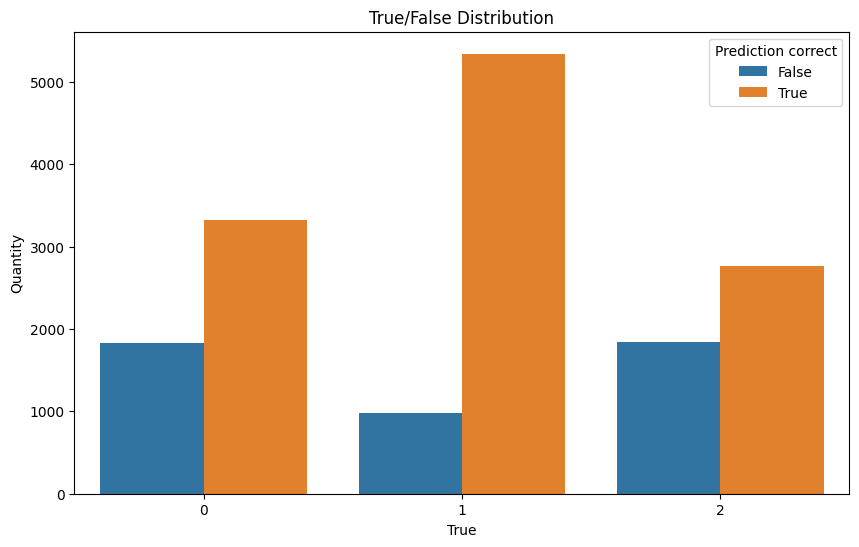

In [26]:
best_model_1 = gsearch_1.best_estimator_

y_pred_cv = cross_val_predict(best_model_1,
                              X_train_encoded,
                              y_train_encoded,
                              cv=cv_counts,
                              method='predict')

errors_df_logreg = pd.DataFrame({
    'True': y_train_encoded,
    'Predicted': y_pred_cv,
    'Correct': y_train_encoded == y_pred_cv
})

plt.figure(figsize=(10, 6))
sns.countplot(x='True', hue='Correct', data=errors_df_logreg)
plt.title('True/False Distribution')
plt.xlabel('True')
plt.ylabel('Quantity')
plt.legend(title='Prediction correct')
plt.show()

/tmp/ipykernel_10022/3377234082.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=final_df, ax=axes[i // 2, i % 2], palette='coolwarm')
/tmp/ipykernel_10022/3377234082.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=final_df, ax=axes[i // 2, i % 2], palette='coolwarm')
/tmp/ipykernel_10022/3377234082.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=final_df, ax=axes[i // 2, i % 2], palette='coolwarm')
/tmp/ipykernel_10022/3377234082.py:7: FutureWarning: 

Passing `palette` wit

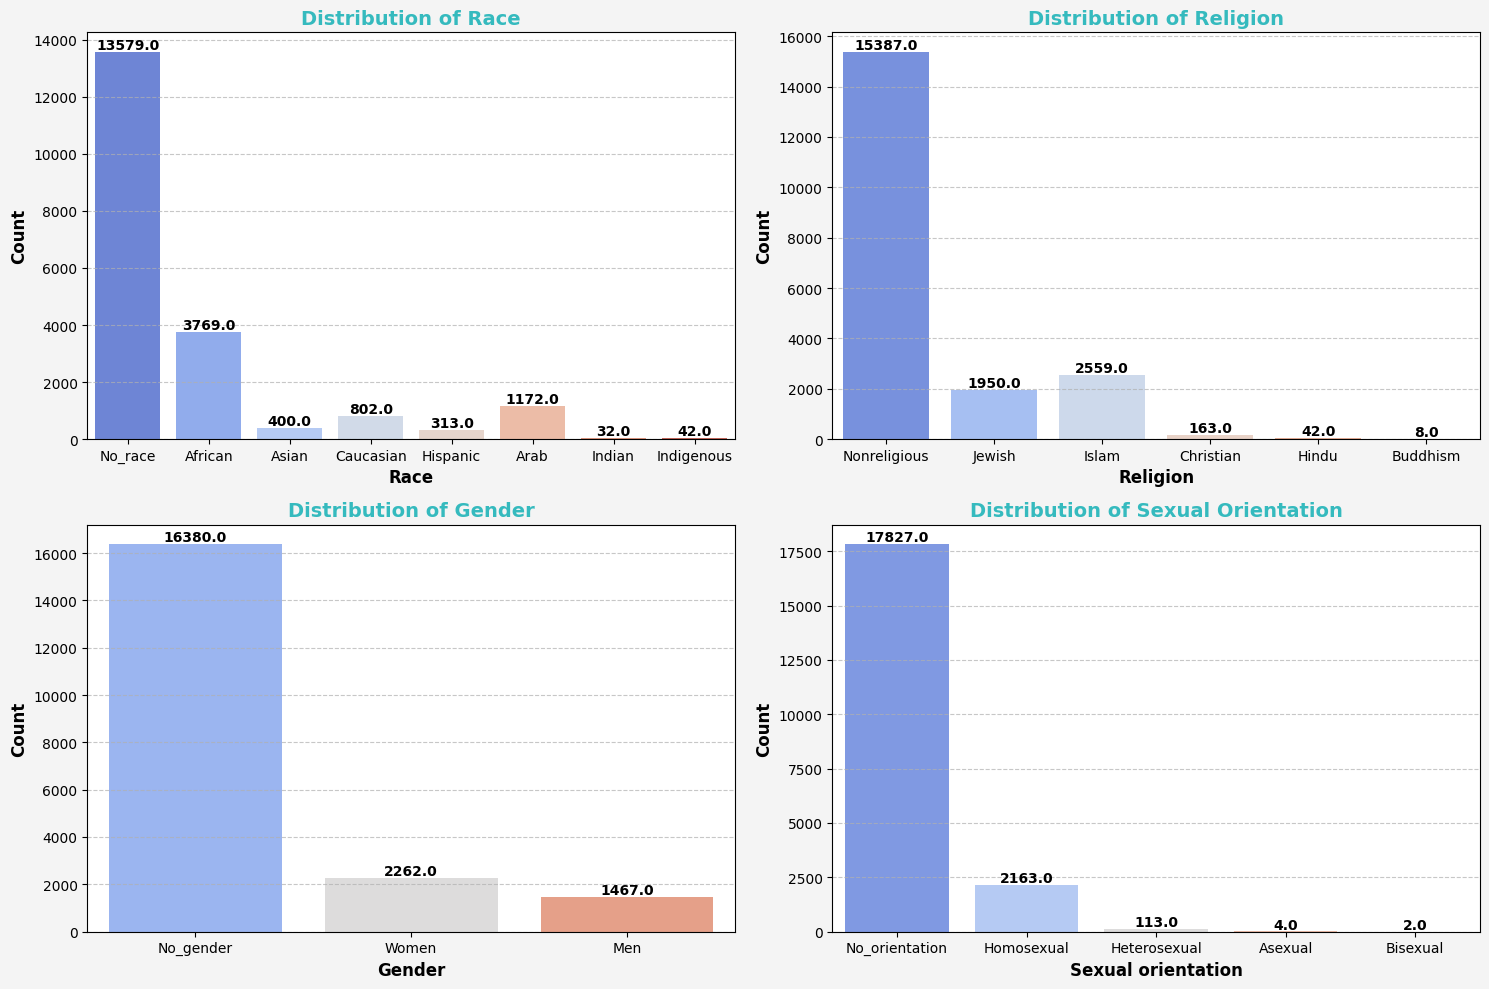

In [27]:
final_df = df  # or df.copy() if you plan to modify it
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.patch.set_facecolor('#f4f4f4')

# Loop through columns and axes to create count plots
for i, col in enumerate(final_df.columns[2:6]):
    ax = sns.countplot(x=col, data=final_df, ax=axes[i // 2, i % 2], palette='coolwarm')
    ax.set_title(f'Distribution of {col}', fontsize=14, weight='bold', color='#35babe')
    ax.set_xlabel(col.capitalize(), fontsize=12, weight='bold')
    ax.set_ylabel('Count', fontsize=12, weight='bold')

    # Annotate counts
    for p in ax.patches:
        ax.annotate(f'{p.get_height()}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontsize=10, color='black', weight='bold')

    # Set grid lines for better readability
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()

# Show the plot
plt.show()

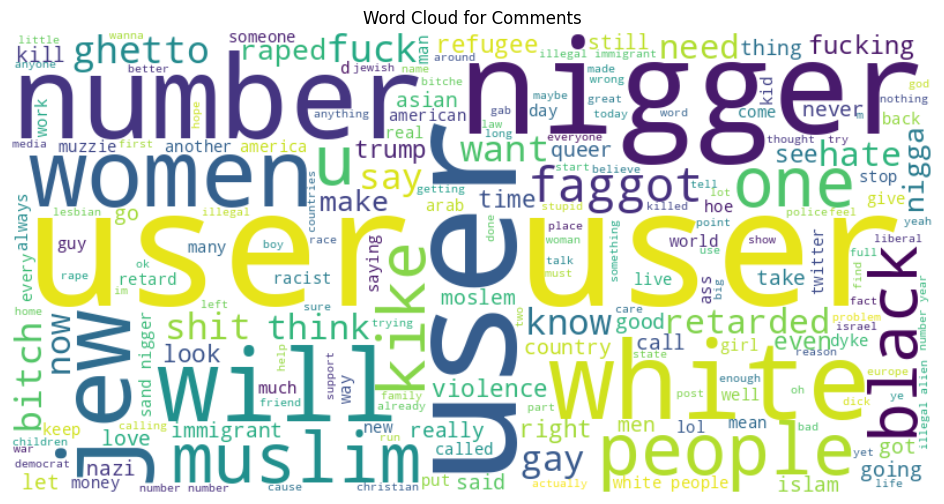

In [28]:
from wordcloud import WordCloud

text = ' '.join(comment for comment in final_df['comment'].dropna())

# Create a word cloud object
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(text)

# Display the word cloud using matplotlib
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Hide axes
plt.title('Word Cloud for Comments')
plt.show()

In [ ]:
%pip install -U kaleido

In [29]:
df['Miscellaneous'].value_counts()

,count
Miscellaneous,
Other,2017
Refugee,1274
Minority,107
Disability,96
Economic,39


In [30]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [33]:
import matplotlib.pyplot as plt

labels = temp_df["label"]
values = temp_df["count"]

fig, ax = plt.subplots()
ax.bar(labels, values)
ax.set_title("Label Distribution")
plt.show()


fig, ax = plt.subplots()
ax.bar(labels, values)
ax.set_title('Label Distribution')

# Save as SVG (or PNG, PDF)
fig.savefig(ARTIFACTS_DIR / 'label_distribution.svg', format='svg')
plt.close()


NameError: name 'temp_df' is not defined

In [34]:
temp_df = df['label'].value_counts().reset_index()
temp_df['label'] = temp_df['label'].str.capitalize()
fig = px.pie(temp_df,values='count',names='label')
fig.update_traces(textinfo='label+percent',textfont_size=16,showlegend=False)
fig.write_image('label_distribution.svg')
fig.show('svg')

/usr/local/lib/python3.13/dist-packages/kaleido/_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.




ValueError: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido


In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
data = df.copy()

data['Miscellaneous'].fillna('None', inplace=True)

data['combined_features'] = data['Race'] + ' ' + data['Religion'] + ' ' + data['Gender'] + ' ' + data['Sexual Orientation'] + ' ' + data['Miscellaneous']
data['text'] = data['comment'] + ' ' + data['combined_features']

X = data['text']
y = data['label']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)
y_pred = model.predict(X_val_tfidf)

accuracy = accuracy_score(y_val, y_pred)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred, target_names=model.classes_))

/tmp/ipykernel_10022/3023996167.py:7: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





Accuracy: 0.71
              precision    recall  f1-score   support

  hatespeech       0.73      0.79      0.76      1325
      normal       0.76      0.82      0.79      1502
   offensive       0.61      0.49      0.55      1195

    accuracy                           0.71      4022
   macro avg       0.70      0.70      0.70      4022
weighted avg       0.71      0.71      0.71      4022



In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from scipy.sparse import hstack

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

data = pd.read_csv('/content/drive/MyDrive/Project1 /Cyberbulling Dataset/final_hateXplain.csv')
data['Miscellaneous'].fillna('None', inplace=True)

X_text = data['comment']
X_race = data['Race']
X_religion = data['Religion']
X_gender = data['Gender']
X_orientation = data['Sexual Orientation']
X_misc = data['Miscellaneous']
y = data['label']

X_text_train, X_text_val, X_race_train, X_race_val, X_religion_train, X_religion_val, \
X_gender_train, X_gender_val, X_orientation_train, X_orientation_val, X_misc_train, X_misc_val, y_train, y_val = \
train_test_split(X_text, X_race, X_religion, X_gender, X_orientation, X_misc, y, test_size=0.2, random_state=42)


tfidf_text = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_text_train_tfidf = tfidf_text.fit_transform(X_text_train)
X_text_val_tfidf = tfidf_text.transform(X_text_val)

tfidf_race = TfidfVectorizer()
tfidf_religion = TfidfVectorizer()
tfidf_gender = TfidfVectorizer()
tfidf_orientation = TfidfVectorizer()
tfidf_misc = TfidfVectorizer()

X_race_train_tfidf = tfidf_race.fit_transform(X_race_train)
X_race_val_tfidf = tfidf_race.transform(X_race_val)

X_religion_train_tfidf = tfidf_religion.fit_transform(X_religion_train)
X_religion_val_tfidf = tfidf_religion.transform(X_religion_val)

X_gender_train_tfidf = tfidf_gender.fit_transform(X_gender_train)
X_gender_val_tfidf = tfidf_gender.transform(X_gender_val)

X_orientation_train_tfidf = tfidf_orientation.fit_transform(X_orientation_train)
X_orientation_val_tfidf = tfidf_orientation.transform(X_orientation_val)

X_misc_train_tfidf = tfidf_misc.fit_transform(X_misc_train)
X_misc_val_tfidf = tfidf_misc.transform(X_misc_val)

X_train_tfidf = hstack([X_text_train_tfidf, X_race_train_tfidf, X_religion_train_tfidf, X_gender_train_tfidf, X_orientation_train_tfidf, X_misc_train_tfidf])
X_val_tfidf = hstack([X_text_val_tfidf, X_race_val_tfidf, X_religion_val_tfidf, X_gender_val_tfidf, X_orientation_val_tfidf, X_misc_val_tfidf])

model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)
y_pred = model.predict(X_val_tfidf)

accuracy = accuracy_score(y_val, y_pred)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred, target_names=model.classes_))

/tmp/ipykernel_706/1537875536.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Miscellaneous'].fillna('None', inplace=True)


Accuracy: 0.72
              precision    recall  f1-score   support

  hatespeech       0.73      0.77      0.75      1325
      normal       0.77      0.83      0.80      1502
   offensive       0.60      0.51      0.55      1195

    accuracy                           0.72      4022
   macro avg       0.70      0.70      0.70      4022
weighted avg       0.71      0.72      0.71      4022

